In [1]:
#import necessary libraries
import pandas as pd

In [2]:
#load dataset
retail_data=pd.read_csv('retail_store_sales.csv')

In [3]:
#dataset overview
print("The first 5 rows of the dataset:")
print(retail_data.head())
print("\nDataset shape:")
print(retail_data.shape)
print("\nDataset info:")
print(retail_data.info())
print("\nDataset description:")
print(retail_data.describe())
print("\nDataset columns:")
print(retail_data.columns)

The first 5 rows of the dataset:
  Transaction ID Customer ID       Category          Item  Price Per Unit  \
0    TXN_6867343     CUST_09     Patisserie   Item_10_PAT            18.5   
1    TXN_3731986     CUST_22  Milk Products  Item_17_MILK            29.0   
2    TXN_9303719     CUST_02       Butchers   Item_12_BUT            21.5   
3    TXN_9458126     CUST_06      Beverages   Item_16_BEV            27.5   
4    TXN_4575373     CUST_05           Food   Item_6_FOOD            12.5   

   Quantity  Total Spent  Payment Method Location Transaction Date  \
0      10.0        185.0  Digital Wallet   Online       2024-04-08   
1       9.0        261.0  Digital Wallet   Online       2023-07-23   
2       2.0         43.0     Credit Card   Online       2022-10-05   
3       9.0        247.5     Credit Card   Online       2022-05-07   
4       7.0         87.5  Digital Wallet   Online       2022-10-02   

  Discount Applied  
0             True  
1             True  
2            False  

In [4]:
#missing values
print("Missing values in each column:")
print(retail_data.isnull().sum())

#check for uniqueness and duplicates
print("\nNumber of unique values in each column:")
print(retail_data.nunique())
print("\nNumber of duplicate rows:")
print(retail_data.duplicated().sum())

Missing values in each column:
Transaction ID         0
Customer ID            0
Category               0
Item                1213
Price Per Unit       609
Quantity             604
Total Spent          604
Payment Method         0
Location               0
Transaction Date       0
Discount Applied    4199
dtype: int64

Number of unique values in each column:
Transaction ID      12575
Customer ID            25
Category                8
Item                  200
Price Per Unit         25
Quantity               10
Total Spent           227
Payment Method          3
Location                2
Transaction Date     1114
Discount Applied        2
dtype: int64

Number of duplicate rows:
0


In [5]:
#data types of columns
print("Numeric columns:")
numeric_columns = retail_data.select_dtypes(include=['number']).columns
print(numeric_columns)
print("\nCategorical columns:")
categorical_columns = retail_data.select_dtypes(include=['object']).columns
print(categorical_columns)

Numeric columns:
Index(['Price Per Unit', 'Quantity', 'Total Spent'], dtype='object')

Categorical columns:
Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Payment Method',
       'Location', 'Transaction Date', 'Discount Applied'],
      dtype='object')


In [6]:
#check non positive values in numeric columns
for col in retail_data.select_dtypes(include=['number']).columns:
    non_positive_count = (retail_data[col] <= 0).sum()
    print(f"Column '{col}' has {non_positive_count} non-positive values.")

Column 'Price Per Unit' has 0 non-positive values.
Column 'Quantity' has 0 non-positive values.
Column 'Total Spent' has 0 non-positive values.


In [7]:
#check if total money spent is actually price*quantity
calculated_total_spent = retail_data['Price Per Unit'] * retail_data['Quantity']
#create filter to only check rows with no missing values
val_filtered=retail_data['Price Per Unit'].notnull() & retail_data['Quantity'].notnull() & retail_data['Total Spent'].notnull()
#compare calculated total spent with actual total spent for rows with no missing values
mismatches=(retail_data.loc[val_filtered, 'Total Spent'] != calculated_total_spent[val_filtered]).sum()
print(f"Number of mismatches: {mismatches}")

Number of mismatches: 0


In [8]:
#date validation check
#covert date from string to datetime objects
dates_converted = pd.to_datetime(retail_data['Transaction Date'], errors='coerce')
print(f"Invalid dates: {dates_converted.isnull().sum()}")
print(f"Date range: {dates_converted.min().date()} to {dates_converted.max().date()}")

Invalid dates: 0
Date range: 2022-01-01 to 2025-01-18


In [9]:
#create copy of data 
clean_retail_data = retail_data.copy()

In [10]:
#convert string dates to datetime objects in the copy
clean_retail_data['Transaction Date'] = pd.to_datetime(clean_retail_data['Transaction Date'], errors='coerce')

In [11]:
clean_retail_data.isnull().sum()

Transaction ID         0
Customer ID            0
Category               0
Item                1213
Price Per Unit       609
Quantity             604
Total Spent          604
Payment Method         0
Location               0
Transaction Date       0
Discount Applied    4199
dtype: int64

In [12]:
#handle categorical missing values
clean_retail_data['Item']=clean_retail_data['Item'].fillna('Unknown')
clean_retail_data['Discount Applied']=clean_retail_data['Discount Applied'].map({True:'True',False:'False'}).fillna('Unknown')

In [13]:
#check rows with missing price but had quantity and total spent
missing_price_mask=retail_data['Price Per Unit'].isnull()
valid_dependencies=retail_data['Quantity'].notnull() & retail_data['Total Spent'].notnull()
recoverable_prices=(missing_price_mask & valid_dependencies).sum()
print(f"Number of recoverable prices: {recoverable_prices}")

Number of recoverable prices: 609


In [14]:
#handle 'Price Per Unit' missing values using math
clean_retail_data['Price Per Unit'] = clean_retail_data['Price Per Unit'].fillna(clean_retail_data['Total Spent'] / clean_retail_data['Quantity'])

In [15]:
retail_data['Quantity'].describe()

count    11971.000000
mean         5.536380
std          2.857883
min          1.000000
25%          3.000000
50%          6.000000
75%          8.000000
max         10.000000
Name: Quantity, dtype: float64

In [16]:
#handle 'Quantity' missing values using median
clean_retail_data['Quantity'] = clean_retail_data.groupby('Category')['Quantity'].transform(lambda x: x.fillna(x.median()))
#group data by category, calculate median for each group then fill every group with its median

In [17]:
#handle 'Total Spent' missing values using math
clean_retail_data['Total Spent']=clean_retail_data['Total Spent'].fillna(
    clean_retail_data['Price Per Unit']*clean_retail_data['Quantity']
)

What information is giving us more information about the customers?

In [18]:
customer_summary=clean_retail_data.groupby('Customer ID').agg(
    Total_Spent=('Total Spent','sum'),
    Total_Transactions=('Transaction ID','count'),
    Average_Order_Value=('Total Spent','mean')
).reset_index()

Top 5 Customers by Spend:
   Customer ID  Total_Spent
23     CUST_24      71798.5
7      CUST_08      70776.5
4      CUST_05      70562.5
12     CUST_13      68799.5
22     CUST_23      68385.5

Top 5 Customers by Frequency:
   Customer ID  Total_Transactions
4      CUST_05                 544
23     CUST_24                 543
12     CUST_13                 534
7      CUST_08                 533
8      CUST_09                 519


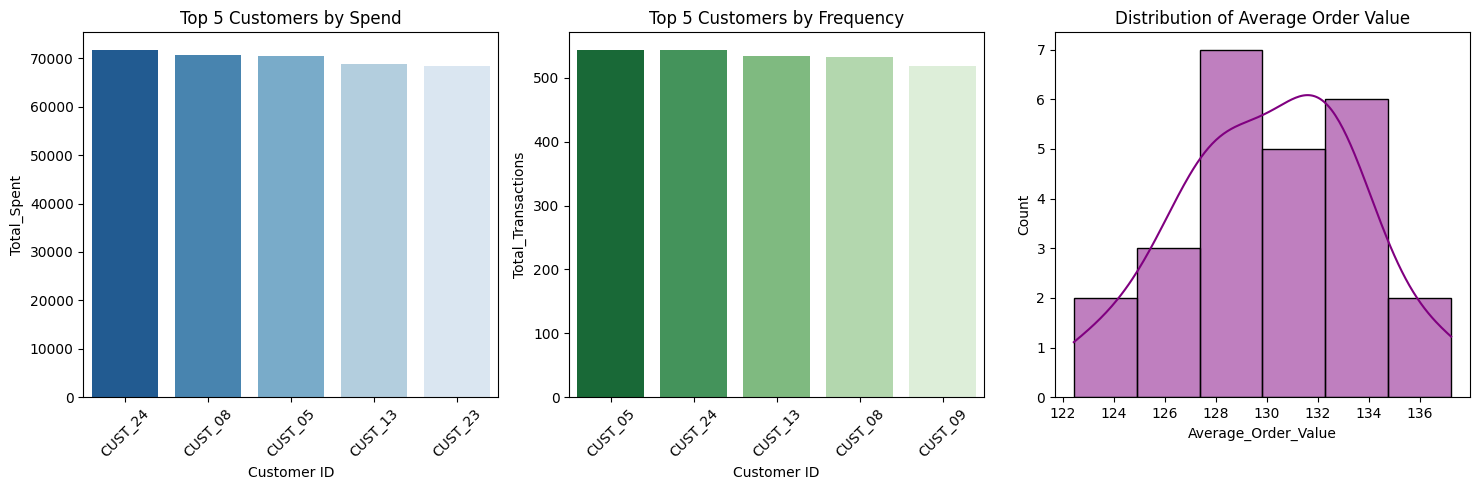

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

#top 5 customers by total spent
top_5_spend = customer_summary.nlargest(5, 'Total_Spent')
print("Top 5 Customers by Spend:")
print(top_5_spend[['Customer ID', 'Total_Spent']])

#top 5 customers by total transactions
top_5_frequency = customer_summary.nlargest(5, 'Total_Transactions')
print("\nTop 5 Customers by Frequency:")
print(top_5_frequency[['Customer ID', 'Total_Transactions']])

#visualize
plt.figure(figsize=(15, 5))

#plot 1
plt.subplot(1, 3, 1)
sns.barplot(data=top_5_spend, x='Customer ID', y='Total_Spent', hue='Customer ID', palette='Blues_r', legend=False)
plt.title('Top 5 Customers by Spend')
plt.xticks(rotation=45)

#plot 2
plt.subplot(1, 3, 2)
sns.barplot(data=top_5_frequency, x='Customer ID', y='Total_Transactions', hue='Customer ID', palette='Greens_r', legend=False)
plt.title('Top 5 Customers by Frequency')
plt.xticks(rotation=45)

#plot 3
plt.subplot(1, 3, 3)
sns.histplot(data=customer_summary, x='Average_Order_Value', kde=True, color='purple')
plt.title('Distribution of Average Order Value')

plt.tight_layout()
plt.show()

CUST_24 and CUST_05 are our power customers because they appear both in total spend and total transcations top 5.

In [21]:
category_summary = clean_retail_data.groupby('Category').agg(
    Total_Sales=('Total Spent','sum'),
    Transactions=('Transaction ID','count')
).reset_index()

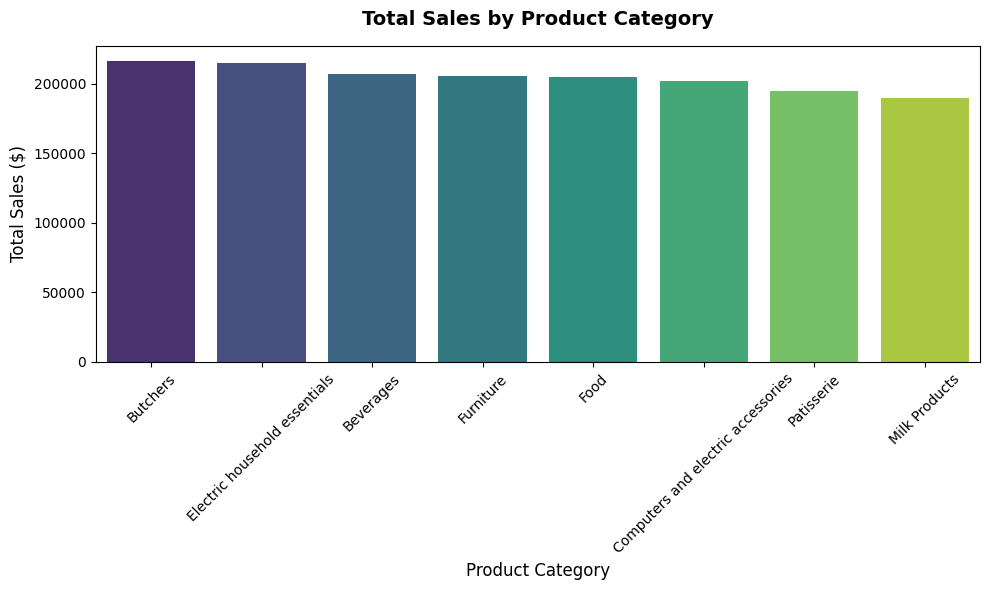

In [22]:
#sort data by total sales
category_summary_sorted = category_summary.sort_values(by='Total_Sales', ascending=False)

#visualize
plt.figure(figsize=(10, 6))

#generate bar chart
sns.barplot(data=category_summary_sorted, x='Category', y='Total_Sales', palette='viridis', hue='Category', legend=False)

#format labels and titles
plt.title('Total Sales by Product Category', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

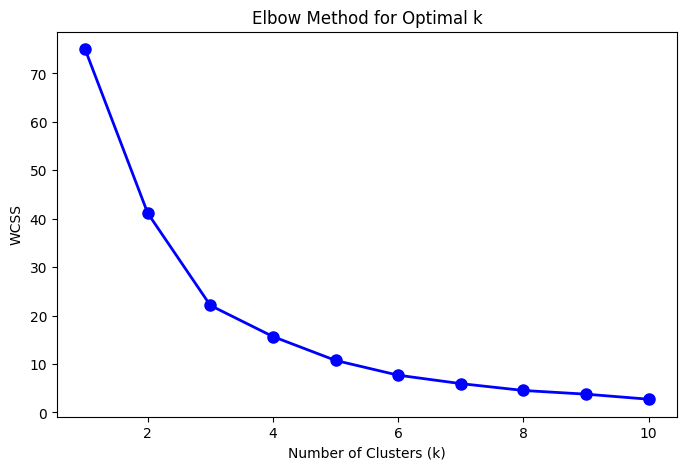

In [26]:
#find customer segments
#necessary libraries
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

#aggregate features per customer
customer_features=clean_retail_data.groupby('Customer ID').agg(
    Total_Spent=('Total Spent','sum'),
    Total_Transactions=('Transaction ID','count'),
    Average_Order_Value=('Total Spent','mean'),
).reset_index()

#select features for clustering
X=customer_features[['Total_Spent','Total_Transactions','Average_Order_Value']]

#scale features
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

#calculate wcss and silhoutte scores
wcss = []
for k in range(1,11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

#plot elbow curve
plt.figure(figsize=(8,5))
plt.plot(range(1,11), wcss, 'bo-', linewidth=2, markersize=8)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.title('Elbow Method for Optimal k')
plt.show()

k=2, silhouette=0.433
k=3, silhouette=0.435
k=4, silhouette=0.433
k=5, silhouette=0.473
k=6, silhouette=0.482
k=7, silhouette=0.452
k=8, silhouette=0.459
k=9, silhouette=0.431
k=10, silhouette=0.433


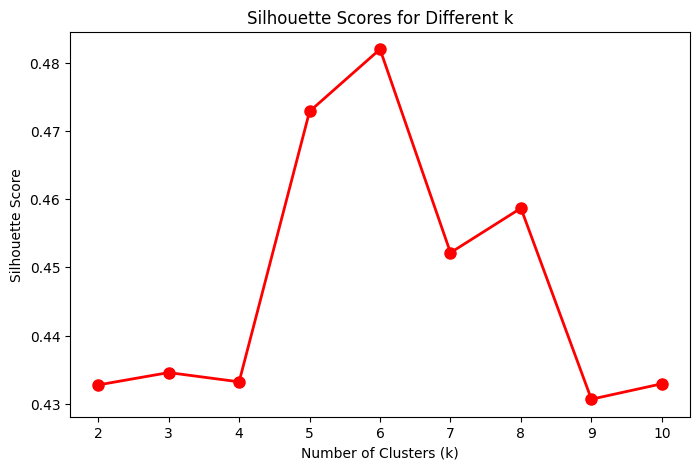

In [27]:
silhouette_scores = []
K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print(f"k={k}, silhouette={score:.3f}")

plt.figure(figsize=(8,5))
plt.plot(K, silhouette_scores, 'ro-', linewidth=2, markersize=8)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Scores for Different k')
plt.xticks(K)
plt.show()

In [29]:
#Fit KMeans with k=3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
customer_features['Cluster'] = kmeans.fit_predict(X_scaled)

print(customer_features[['Customer ID','Total_Spent','Total_Transactions','Average_Order_Value','Cluster']].head())

  Customer ID  Total_Spent  Total_Transactions  Average_Order_Value  Cluster
0     CUST_01      62077.0                 507           122.439842        1
1     CUST_02      65147.5                 488           133.498975        0
2     CUST_03      63809.0                 465           137.223656        0
3     CUST_04      64501.0                 474           136.078059        0
4     CUST_05      70562.5                 544           129.710478        2


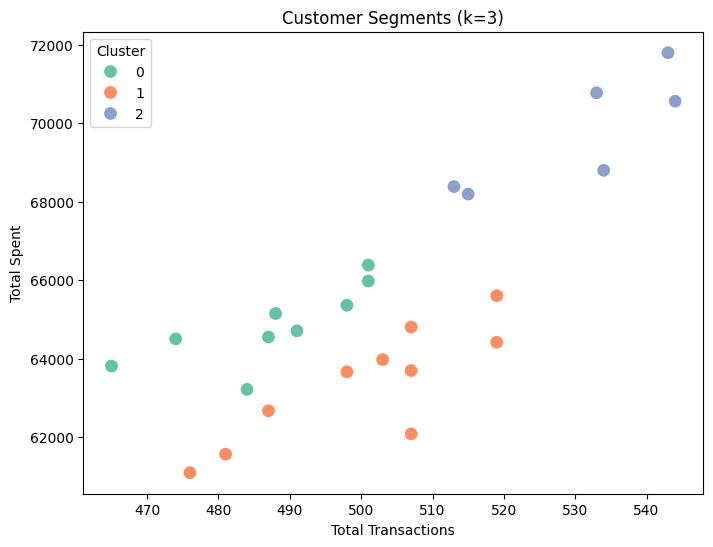

In [31]:
#visualize clusters
plt.figure(figsize=(8,6))
sns.scatterplot(x='Total_Transactions', y='Total_Spent',hue='Cluster', palette='Set2', data=customer_features, s=100)
plt.title("Customer Segments (k=3)")
plt.xlabel("Total Transactions")
plt.ylabel("Total Spent")
plt.show()

Cluster 0: low-average spend, low transactions (get to visit more) ####target
Cluster 1: low spend, average transactions (get them to spend more when they visit)
Cluster 2: VIPs (high spend, high transactions), give exclusive rewards/offers

In [32]:
customer_features.groupby('Cluster').agg(
    Avg_Spend=('Total_Spent','mean'),
    Avg_Transactions=('Total_Transactions','mean'),
    Avg_Order_Value=('Average_Order_Value','mean'),
    Customer_Count=('Customer ID','count')
)

,Avg_Spend,Avg_Transactions,Avg_Order_Value,Customer_Count
Cluster,,,,
0,64849.00,487.666667,133.017987,9
1,63353.70,500.400000,126.640967,10
2,69752.75,530.333333,131.547271,6


In [33]:
#merge cluster labels back to transactions
transactions_with_clusters = clean_retail_data.merge(customer_features[['Customer ID','Cluster']],on='Customer ID',how='left')

#aggregate category spend per cluster
cluster_category_summary = transactions_with_clusters.groupby(['Cluster','Category']).agg(
    Total_Sales=('Total Spent','sum'),
    Transactions=('Transaction ID','count')
).reset_index()

#find top category per cluster
top_category_per_cluster = cluster_category_summary.loc[
    cluster_category_summary.groupby('Cluster')['Total_Sales'].idxmax()
]

print(top_category_per_cluster)

    Cluster   Category  Total_Sales  Transactions
1         0   Butchers      79443.0           570
13        1  Furniture      85273.0           663
20        2       Food      55869.0           424


In [ ]:
Cluster 0: spend more on meat products (Target with premium meat products)
Cluster 1: spend more on furniture (Target with furniture offers e.g. spend X amount, free delivery)
Cluster 2: spend more on food purchases (Target with exclusive food discounts)